saved Fig_07_noise/outputs/main_w_LLM.pdf
saved Fig_07_noise/outputs/main_w_LLM.png


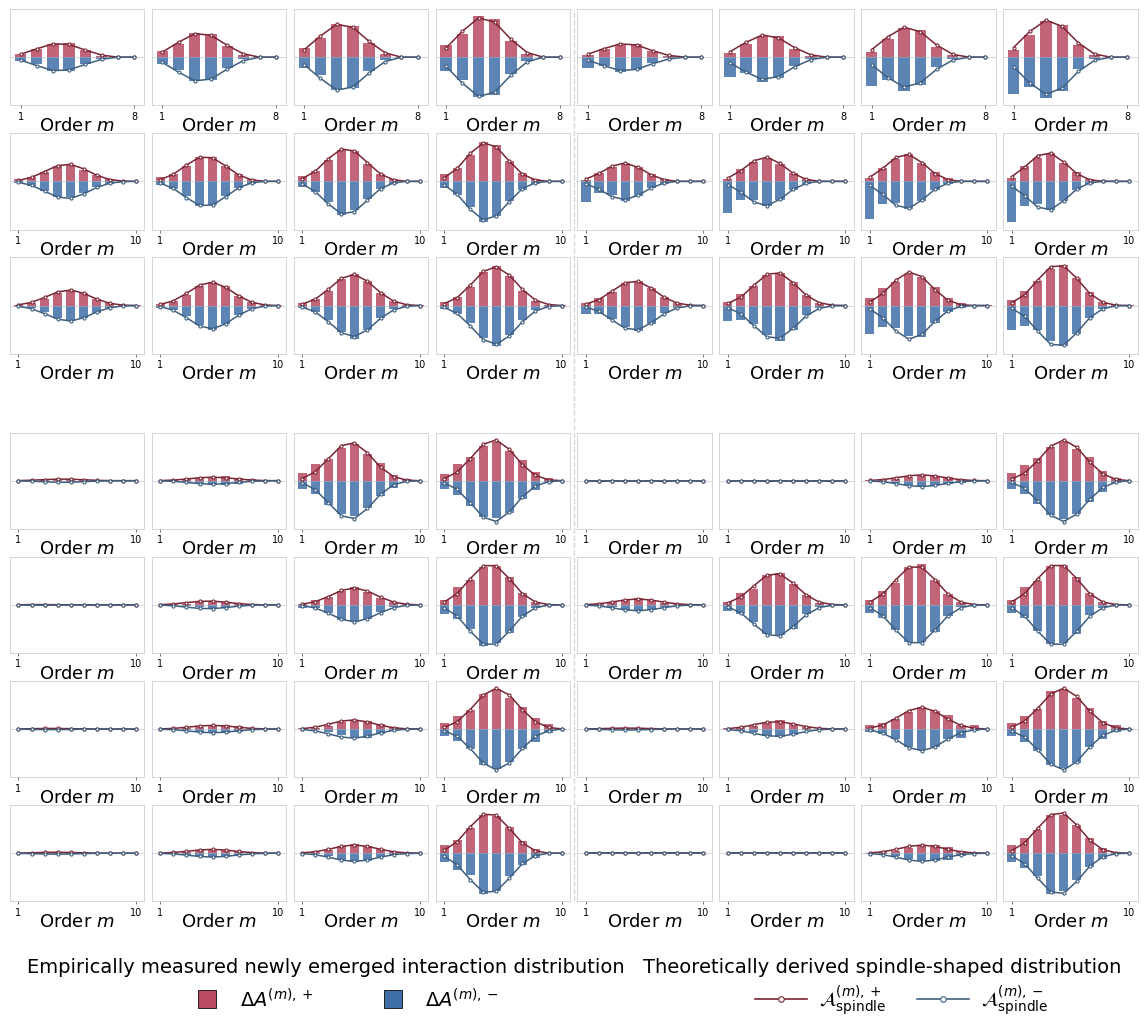

In [1]:
"""Render Fig.7 with LLM rows inside the original axes grid."""
import json
from pathlib import Path
import sys

import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np


PACKAGE_ROOT = next((path for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (path / "interactions").is_dir()), None)
if PACKAGE_ROOT is None:
    raise FileNotFoundError("Run this notebook from inside AIJ_fig_submit.")
FIGURE_DIR = PACKAGE_ROOT / "Fig_07_noise"
ROOT = FIGURE_DIR / "source"
sys.path.insert(0, str(PACKAGE_ROOT / "shared"))

from tool import compute_llm_decomposition_cached, save_figure  # noqa: E402


LLM_TASK = "finance"
LLM_NOISE_ROOT_BASE = PACKAGE_ROOT / "interactions" / "llm" / "noise" / LLM_TASK
LLM_CACHE_DIR = PACKAGE_ROOT / "interactions" / "llm" / "noise_decomposition_cache"
LLM_MODELS = [
    ("Qwen2.5-7B", "Qwen__Qwen2.5-7B"),
    ("Llama-3-8B", "meta-llama__Meta-Llama-3-8B"),
    ("GLM-Z1-9B", "zai-org__GLM-Z1-9B-0414"),
    ("Phi-4", "microsoft__phi-4"),
]
LLM_PARAMETER_LEVELS = [1e-8, 3e-8, 1e-7, 3e-7]
LLM_EMBEDDING_LEVELS = [1e-8, 3e-8, 1e-7, 3e-7]

# ==================== 布局调节参数（直接修改这里）====================
# 上方三行与下方四行之间的额外空白；0.10 约为一行文字高度。
GROUP_SPACER_RATIO = 0.24
# 所有子图行之间的间距；数值越小，行与行越紧凑。
ROW_SPACING = 0.32
# 保持每个子图与原始版等高。设为 1.0 时完全恢复原始子图高度；
# 小于 1.0 可进一步缩小子图，大于 1.0 可放大子图。
SUBPLOT_HEIGHT_SCALE = 1.0
# 为底部分组标题和图例预留的画布高度；数值越小，底部越紧凑。
BOTTOM_MARGIN = 0.115
# 底部分组标题和图例的纵坐标；数值越小，内容越靠近图像底边。
BOTTOM_TITLE_Y = 0.052
BOTTOM_LEGEND_Y = 0.020
# 画布左右与顶部边距；通常无需调整。
LEFT_MARGIN = 0.018
RIGHT_MARGIN = 0.99
TOP_MARGIN = 0.982
# ==================================================================


def load_notebook_defs():
    notebook = json.loads((ROOT / "main.ipynb").read_text(encoding="utf-8"))
    namespace = {"__name__": "fig7_notebook_defs"}
    exec("".join(notebook["cells"][0]["source"]), namespace)
    return namespace


def plot_small_row(ns, axes, row, config):
    samples = ns["get_row_shared_samples"](config)
    parameter_max = 0.0
    attack_max = 0.0
    for col, level in enumerate(config["parameter_levels"]):
        decomposition = ns["compute_shared_sample_decomposition"](config["local_root"], samples, "parameter", level)
        parameter_max = max(parameter_max, ns["plot_fig3_style"](axes[row, col], decomposition))
    for offset, level in enumerate(config["attack_levels"]):
        col = offset + ns["N_PARAM_COLS"]
        decomposition = ns["compute_shared_sample_decomposition"](config["local_root"], samples, "attack", level)
        attack_max = max(attack_max, ns["plot_fig3_style"](axes[row, col], decomposition))
    format_row(ns, axes[row], parameter_max, attack_max)


def plot_llm_row(ns, axes, row, model_id):
    model_noise_root = LLM_NOISE_ROOT_BASE / model_id
    clean_root = model_noise_root / "parameter_noise_lambda=0"
    parameter_max = 0.0
    embedding_max = 0.0
    for col, level in enumerate(LLM_PARAMETER_LEVELS):
        decomposition = compute_llm_decomposition_cached(
            LLM_CACHE_DIR, clean_root, model_noise_root, "parameter", level, mode="newly_emerged", tau=0.02
        )
        parameter_max = max(parameter_max, ns["plot_fig3_style"](axes[row, col], decomposition))
    for offset, level in enumerate(LLM_EMBEDDING_LEVELS):
        col = offset + ns["N_PARAM_COLS"]
        decomposition = compute_llm_decomposition_cached(
            LLM_CACHE_DIR, clean_root, model_noise_root, "embedding", level, mode="newly_emerged", tau=0.02
        )
        embedding_max = max(embedding_max, ns["plot_fig3_style"](axes[row, col], decomposition))
    format_row(ns, axes[row], parameter_max, embedding_max)


def format_row(ns, row_axes, left_max, right_max):
    left_lim = max(left_max * 1.18, 1e-12)
    right_lim = max(right_max * 1.18, 1e-12)
    for col, ax in enumerate(row_axes):
        group_lim = left_lim if col < ns["N_PARAM_COLS"] else right_lim
        ax.set_ylim(-group_lim, group_lim)
        ax.tick_params(axis="x", labelbottom=True)
        ax.set_xlabel(r"Order $m$", fontsize=ns["X_LABEL_FONT_SIZE"], labelpad=0)
        ax.xaxis.set_label_coords(0.5, -0.11)


def add_bottom_legend(ns, fig, axes, bottom_margin, top_margin):
    sep_x = (
        axes[0, ns["N_PARAM_COLS"] - 1].get_position().x1
        + axes[0, ns["N_PARAM_COLS"]].get_position().x0
    ) / 2
    fig.add_artist(
        Line2D(
            [sep_x, sep_x], [bottom_margin, top_margin],
            transform=fig.transFigure, color="#D2D8E0", linestyle="--", linewidth=1.0, alpha=1.0,
        )
    )
    fig.text(
        0.29, BOTTOM_TITLE_Y, "Empirically measured newly emerged interaction distribution",
        ha="center", va="center", fontsize=ns["BOTTOM_TITLE_FONT_SIZE"], transform=fig.transFigure,
    )
    fig.text(
        0.77, BOTTOM_TITLE_Y, "Theoretically derived spindle-shaped distribution",
        ha="center", va="center", fontsize=ns["BOTTOM_TITLE_FONT_SIZE"], transform=fig.transFigure,
    )

    def add_patch_item(x, y, color, label):
        fig.patches.append(
            mpatches.Rectangle(
                (x, y - 0.009), 0.016, 0.018, transform=fig.transFigure,
                facecolor=color, edgecolor="#222222", linewidth=0.7,
            )
        )
        fig.text(x + 0.036, y, label, ha="left", va="center",
                 fontsize=ns["LEGEND_FONT_SIZE"], transform=fig.transFigure)

    def add_line_item(x, y, color, label):
        x0, x1 = x, x + 0.045
        xm = (x0 + x1) / 2
        fig.add_artist(Line2D([x0, x1], [y, y], transform=fig.transFigure, color=color, linewidth=1.2))
        fig.add_artist(
            Line2D(
                [xm], [y], transform=fig.transFigure, color=color, marker="o",
                markersize=4.0, markerfacecolor="white", markeredgecolor=color,
                markeredgewidth=0.8, linestyle="None",
            )
        )
        fig.text(x + 0.055, y, label, ha="left", va="center",
                 fontsize=ns["LEGEND_FONT_SIZE"], transform=fig.transFigure)

    add_patch_item(0.18, BOTTOM_LEGEND_Y, ns["REAL_POS_COLOR"], r"$\Delta A^{(m),+}$")
    add_patch_item(0.34, BOTTOM_LEGEND_Y, ns["REAL_NEG_COLOR"], r"$\Delta A^{(m),-}$")
    add_line_item(0.66, BOTTOM_LEGEND_Y, ns["THEO_POS_COLOR"], r"$\mathcal{A}^{(m),+}_{\mathrm{spindle}}$")
    add_line_item(0.80, BOTTOM_LEGEND_Y, ns["THEO_NEG_COLOR"], r"$\mathcal{A}^{(m),-}_{\mathrm{spindle}}$")


def main():
    ns = load_notebook_defs()
    ns["apply_style"](ns["FONT_SIZE"])
    small_rows = ns["ROWS"]
    total_data_rows = len(small_rows) + len(LLM_MODELS)
    # Use the original layout to preserve the physical height of every subplot.
    original_grid_units = total_data_rows + 0.55
    original_gap_units = 0.35 * (total_data_rows + 1 - 1)
    original_fig_height = ns["FIGSIZE"][1] * original_grid_units / len(small_rows)
    original_axis_height = original_fig_height * (0.982 - 0.16) / (original_grid_units + original_gap_units)
    current_grid_units = total_data_rows + GROUP_SPACER_RATIO
    current_gap_units = ROW_SPACING * (total_data_rows + 1 - 1)
    fig_height = (
        original_axis_height * SUBPLOT_HEIGHT_SCALE
        * (current_grid_units + current_gap_units) / (TOP_MARGIN - BOTTOM_MARGIN)
    )
    fig = plt.figure(figsize=(ns["FIGSIZE"][0], fig_height))
    height_ratios = [1] * len(small_rows) + [GROUP_SPACER_RATIO] + [1] * len(LLM_MODELS)
    grid = GridSpec(len(height_ratios), ns["N_COLS"], figure=fig, height_ratios=height_ratios)
    axes = []
    for row in list(range(len(small_rows))) + list(range(len(small_rows) + 1, len(height_ratios))):
        axes.append([fig.add_subplot(grid[row, col]) for col in range(ns["N_COLS"])])
    axes = np.asarray(axes, dtype=object)
    spacer_ax = fig.add_subplot(grid[len(small_rows), :])
    spacer_ax.axis("off")

    for row, config in enumerate(small_rows):
        plot_small_row(ns, axes, row, config)
    for idx, (_model_label, model_id) in enumerate(LLM_MODELS):
        plot_llm_row(ns, axes, len(small_rows) + idx, model_id)

    plt.subplots_adjust(
        left=LEFT_MARGIN, right=RIGHT_MARGIN, bottom=BOTTOM_MARGIN,
        top=TOP_MARGIN, wspace=0.055, hspace=ROW_SPACING,
    )
    add_bottom_legend(ns, fig, axes, BOTTOM_MARGIN, TOP_MARGIN)
    pdf, png = save_figure(fig, FIGURE_DIR / "outputs", "main_w_LLM")
    print(f"saved {pdf}")
    print(f"saved {png}")


if __name__ == "__main__":
    main()